<a href="https://colab.research.google.com/github/dlgustj12/Linear-Algebra/blob/main/202221061_%EC%9D%B4%ED%98%84%EC%84%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [2]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [3]:
def draw_rectangle(ax, p1, p2, p3, p4, color=None):
  # color=None 이면 기본 파란색, 지정하면 해당 색으로 채움
  my_polygon = Polygon([p1, p2, p3, p4], color=color)
  ax.add_patch(my_polygon)

In [4]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

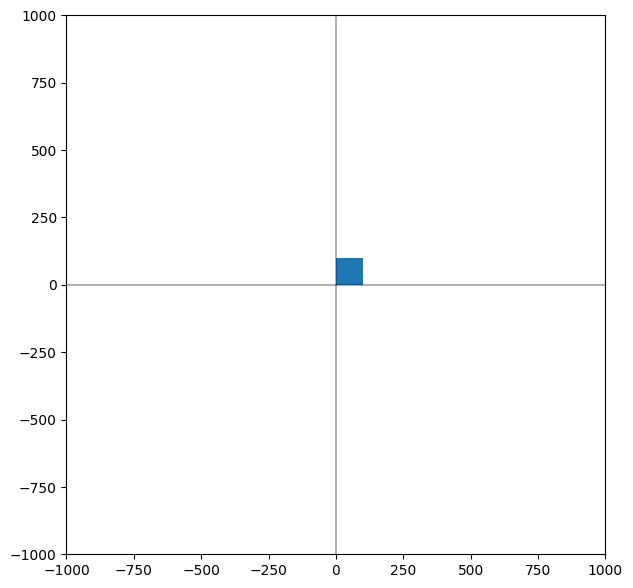

In [5]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* reflect_origin(p)  
* reflect_yx(p)  

In [6]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [7]:
# 점 p를 원점 기준으로 theta(라디안)만큼 반시계 방향으로 회전시킨 점 q를 구할 것
# q = R(theta) p
def rotate(p, theta):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 회전 변환 행렬 생성
  m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                [np.sin(theta),  np.cos(theta), 0.0],
                [0.0,            0.0,           1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [8]:
# 점 p를 x축 방향으로 sx배, y축 방향으로 sy배 크기 변환한 점 q를 구할 것
# q = S(sx, sy) p
def scale(p, sx, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 크기 변환 행렬 생성
  m = np.array([[sx,  0.0, 0.0],
                [0.0, sy,  0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [9]:
# 점 p를 x축 방향으로 기울인(밀림) 점 q를 구할 것: x' = x + sx*y
# q = Shx(sx) p
def shear_x(p, sx):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x축 기울기 변환 행렬 생성
  m = np.array([[1.0, sx,  0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q


# 점 p를 y축 방향으로 기울인(밀림) 점 q를 구할 것: y' = y + sy*x
# q = Shy(sy) p
def shear_y(p, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y축 기울기 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0],
                [sy,  1.0, 0.0],
                [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [10]:
# 반전(대칭) 변환
# reflect_x : x축 대칭   (x, y) -> ( x, -y)
# reflect_y : y축 대칭   (x, y) -> (-x,  y)   <- 강의자료의 Rf_y
# reflect_origin : 원점 대칭 (x, y) -> (-x, -y)
# reflect_yx : y=x 직선 대칭 (x, y) -> ( y,  x)
def reflect_x(p):
  hp = np.array([p[0], p[1], 1.0])                                     # 1. 동차좌표계
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])  # 2. 변환 행렬
  q = np.dot(m, hp)                                                    # 3. 행렬과 벡터의 곱
  return np.array([q[0], q[1]])                                        # 4. 2차원 좌표계

def reflect_y(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

def reflect_origin(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

def reflect_yx(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

In [11]:
# ---------- 크기 상수 (처음 사각형은 LEN x LEN) ----------
COCKPIT_R  = 332   # 조종석 마름모의 중심~꼭짓점 거리

ARM_LEN    = 850   # 날개축 길이 (원점 ~ 날개 바깥쪽 끝)
ARM_H_OUT  = 42    # 날개 쪽 끝의 반높이
ARM_H_IN   = 144   # 조종석 쪽 끝의 반높이

HOLE_W     = 500   # 연결부 마름모의 반너비 (x축 방향 꼭짓점 거리)
HOLE_H     = 60    # 연결부 마름모의 반높이 (y축 방향 꼭짓점 거리)

WING_X     = 725   # 날개 안쪽 변의 x 위치
WING_W     = 135   # 날개 두께
WING_H_IN  = 400   # 날개 안쪽 변의 반높이
WING_H_OUT = 555   # 날개 바깥쪽 변의 반높이 (안쪽보다 커서 사다리꼴)

In [12]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(s, s)  (회전 후 꼭짓점 거리 = s * LEN/2 * sqrt(2) = COCKPIT_R)
  s = COCKPIT_R / (LEN/2 * np.sqrt(2))
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, np.pi/4)
  q2 = rotate(q2, np.pi/4)
  q3 = rotate(q3, np.pi/4)
  q4 = rotate(q4, np.pi/4)

  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [13]:
# 왼쪽 날개축의 꼭짓점 4개를 계산 (오른쪽 날개축에서도 재사용)
def make_left_arm(p1, p2, p3, p4):
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1 = translate(p1, -LEN/2, -LEN/2)   # 왼쪽 아래  (날개 쪽)
  q2 = translate(p2, -LEN/2, -LEN/2)   # 오른쪽 아래 (조종석 쪽)
  q3 = translate(p3, -LEN/2, -LEN/2)   # 오른쪽 위   (조종석 쪽)
  q4 = translate(p4, -LEN/2, -LEN/2)   # 왼쪽 위     (날개 쪽)

  # 2. 크기 변환: x는 모두 같은 배율, y는 날개 쪽(q1,q4)과 조종석 쪽(q2,q3)을 다르게
  #    -> 날개 쪽은 가늘고 조종석 쪽은 굵은 사다리꼴
  sx = ARM_LEN / LEN
  q1 = scale(q1, sx, ARM_H_OUT / (LEN/2))
  q4 = scale(q4, sx, ARM_H_OUT / (LEN/2))
  q2 = scale(q2, sx, ARM_H_IN  / (LEN/2))
  q3 = scale(q3, sx, ARM_H_IN  / (LEN/2))

  # 3. 이동 변환: 조종석 쪽 끝이 원점(x=0), 날개 쪽 끝이 x=-ARM_LEN 에 오도록
  q1 = translate(q1, -ARM_LEN/2, 0)
  q2 = translate(q2, -ARM_LEN/2, 0)
  q3 = translate(q3, -ARM_LEN/2, 0)
  q4 = translate(q4, -ARM_LEN/2, 0)
  return q1, q2, q3, q4


def draw_left_arm(ax, p1, p2, p3, p4):  # 왼쪽 날개축
  q1, q2, q3, q4 = make_left_arm(p1, p2, p3, p4)
  draw_rectangle(ax, q1, q2, q3, q4)


def draw_right_arm(ax, p1, p2, p3, p4):  # 오른쪽 날개축
  q1, q2, q3, q4 = make_left_arm(p1, p2, p3, p4)

  # 4. y축 반전 변환: 왼쪽 날개축 -> 오른쪽 날개축
  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

In [14]:
def draw_connector_rhombus(ax, p1, p2, p3, p4):  # 날개 연결부: 양쪽을 잇는 하나의 마름모
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 회전 변환: R(pi/4)  -> 정사각형이 마름모(꼭짓점이 축 위에 놓임)가 됨
  q1 = rotate(q1, np.pi/4)
  q2 = rotate(q2, np.pi/4)
  q3 = rotate(q3, np.pi/4)
  q4 = rotate(q4, np.pi/4)

  # 3. 크기 변환: S(sx, sy)  -> x방향으로 길고 y방향으로 납작한 마름모
  half_diag = LEN/2 * np.sqrt(2)           # 회전 직후 꼭짓점~중심 거리
  sx = HOLE_W / half_diag
  sy = HOLE_H / half_diag
  q1 = scale(q1, sx, sy)
  q2 = scale(q2, sx, sy)
  q3 = scale(q3, sx, sy)
  q4 = scale(q4, sx, sy)

  # 4. polygon 그리기: 날개축에 뚫린 틈 처럼 보이도록 배경색(흰색)으로 채움
  draw_rectangle(ax, q1, q2, q3, q4, color='white')

In [15]:
# 왼쪽 날개의 꼭짓점 4개를 계산 (오른쪽 날개에서도 재사용)
def make_left_wing(p1, p2, p3, p4):
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q1 = translate(p1, -LEN/2, -LEN/2)   # 왼쪽 아래  (바깥쪽)
  q2 = translate(p2, -LEN/2, -LEN/2)   # 오른쪽 아래 (안쪽)
  q3 = translate(p3, -LEN/2, -LEN/2)   # 오른쪽 위   (안쪽)
  q4 = translate(p4, -LEN/2, -LEN/2)   # 왼쪽 위     (바깥쪽)

  # 2. 크기 변환: 바깥쪽 변(q1,q4)이 안쪽 변(q2,q3)보다 더 길도록 y 배율을 다르게 -> 사다리꼴
  sx = WING_W / LEN
  q1 = scale(q1, sx, WING_H_OUT / (LEN/2))
  q4 = scale(q4, sx, WING_H_OUT / (LEN/2))
  q2 = scale(q2, sx, WING_H_IN  / (LEN/2))
  q3 = scale(q3, sx, WING_H_IN  / (LEN/2))

  # 3. 이동 변환: 안쪽 변이 x=-WING_X 에 오도록
  dx = -(WING_X + WING_W/2)
  q1 = translate(q1, dx, 0)
  q2 = translate(q2, dx, 0)
  q3 = translate(q3, dx, 0)
  q4 = translate(q4, dx, 0)
  return q1, q2, q3, q4


def draw_left_wing(ax, p1, p2, p3, p4):  # 왼쪽 날개
  q1, q2, q3, q4 = make_left_wing(p1, p2, p3, p4)
  draw_rectangle(ax, q1, q2, q3, q4)


def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개
  q1, q2, q3, q4 = make_left_wing(p1, p2, p3, p4)

  # 4. y축 반전 변환: 왼쪽 날개 -> 오른쪽 날개
  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)
  draw_rectangle(ax, q1, q2, q3, q4)

In [16]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 그리는 순서가 곧 겹치는 순서 (나중에 그린 것이 위에 놓임)

  # 1. 왼쪽 / 오른쪽 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)
  draw_right_arm(ax, p1, p2, p3, p4)

  # 2. 날개축 사이의 마름모 (흰색 틈) 그리기: 날개축 위, 조종석 아래
  draw_connector_rhombus(ax, p1, p2, p3, p4)

  # 3. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 4. 왼쪽 / 오른쪽 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)
  draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

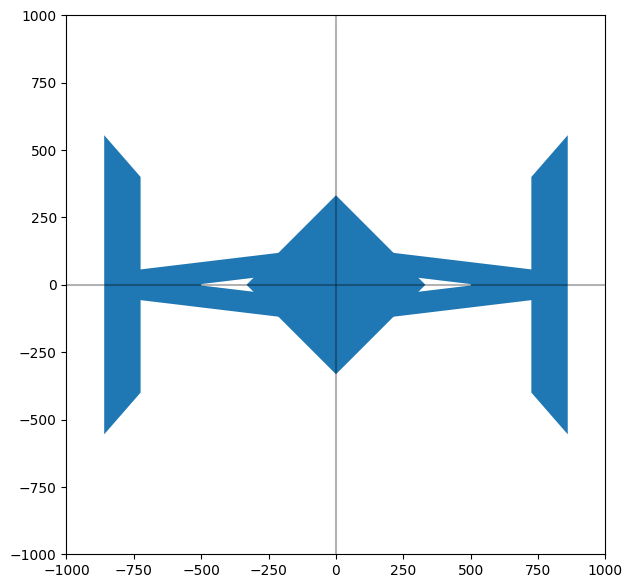

In [17]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()